# **libs**

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd_
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error,r2_score

# **Load dataset**

In [11]:
data = pd.read_csv("TSLA.csv",parse_dates=['Date'])
data.set_index("Date",inplace=True)

In [12]:
data

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2010-06-29,19.000000,25.000000,17.540001,23.889999,23.889999,18766300
2010-06-30,25.790001,30.420000,23.299999,23.830000,23.830000,17187100
2010-07-01,25.000000,25.920000,20.270000,21.959999,21.959999,8218800
2010-07-02,23.000000,23.100000,18.709999,19.200001,19.200001,5139800
2010-07-06,20.000000,20.000000,15.830000,16.110001,16.110001,6866900
...,...,...,...,...,...,...
2020-01-28,568.489990,576.809998,558.080017,566.900024,566.900024,11788500
2020-01-29,575.690002,589.799988,567.429993,580.989990,580.989990,17801500
2020-01-30,632.419983,650.880005,618.000000,640.809998,640.809998,29005700


In [13]:
data.describe()

,Open,High,Low,Close,Adj Close,Volume
count,2416.000000,2416.000000,2416.000000,2416.000000,2416.000000,2.416000e+03
mean,186.271147,189.578224,182.916639,186.403651,186.403651,5.572722e+06
std,118.740163,120.892329,116.857591,119.136020,119.136020,4.987809e+06
min,16.139999,16.629999,14.980000,15.800000,15.800000,1.185000e+05
25%,34.342498,34.897501,33.587501,34.400002,34.400002,1.899275e+06
50%,213.035004,216.745002,208.870002,212.960007,212.960007,4.578400e+06
75%,266.450012,270.927513,262.102501,266.774994,266.774994,7.361150e+06
max,673.690002,786.140015,673.520020,780.000000,780.000000,4.706500e+07


In [14]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2416 entries, 2010-06-29 to 2020-02-03
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Open       2416 non-null   float64
 1   High       2416 non-null   float64
 2   Low        2416 non-null   float64
 3   Close      2416 non-null   float64
 4   Adj Close  2416 non-null   float64
 5   Volume     2416 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 132.1 KB


In [15]:
data.shape

(2416, 6)

In [16]:
data.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2010-06-29,19.000000,25.00,17.540001,23.889999,23.889999,18766300
2010-06-30,25.790001,30.42,23.299999,23.830000,23.830000,17187100
2010-07-01,25.000000,25.92,20.270000,21.959999,21.959999,8218800
2010-07-02,23.000000,23.10,18.709999,19.200001,19.200001,5139800
2010-07-06,20.000000,20.00,15.830000,16.110001,16.110001,6866900


In [10]:
data.tail(10)

,Date,Open,High,Low,Close,Adj Close,Volume
2406,2020-01-21,530.250000,548.580017,528.409973,547.200012,547.200012,17803500
2407,2020-01-22,571.890015,594.500000,559.099976,569.559998,569.559998,31369000
2408,2020-01-23,564.250000,582.000000,555.599976,572.200012,572.200012,19651000
2409,2020-01-24,570.630005,573.859985,554.260010,564.820007,564.820007,14353600
2410,2020-01-27,541.989990,564.440002,539.280029,558.020020,558.020020,13608100
2411,2020-01-28,568.489990,576.809998,558.080017,566.900024,566.900024,11788500
2412,2020-01-29,575.690002,589.799988,567.429993,580.989990,580.989990,17801500
2413,2020-01-30,632.419983,650.880005,618.000000,640.809998,640.809998,29005700
2414,2020-01-31,640.000000,653.000000,632.520020,650.570007,650.570007,15719300
2415,2020-02-03,673.690002,786.140015,673.520020,780.000000,780.000000,47065000


In [18]:
data.columns.isna()

array([False, False, False, False, False, False])

In [34]:
X = data.iloc[:,1].values.reshape(-1,1)
y = data.iloc[:,2].values

In [35]:
X.shape

(2416, 1)

<AxesSubplot:xlabel='Date'>

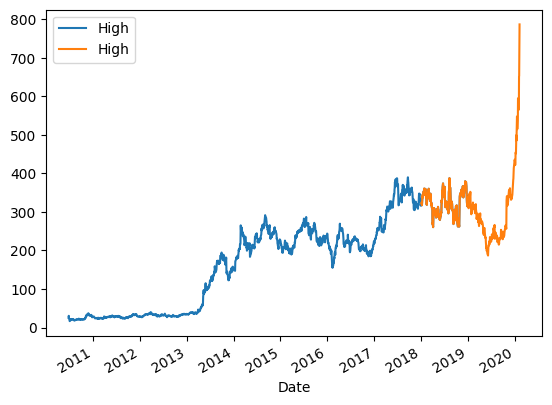

In [36]:
data["High"][:"2018"].plot(legend=True)
data["High"]["2018":].plot(legend=True)

In [37]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)


In [38]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [49]:
y_pred = model.predict(X_test)

In [50]:
mse = mean_squared_error(y_test,y_pred)

In [51]:
mse

13.095870549126822

In [54]:
r2 = r2_score(y_test,y_pred)

In [55]:
r2*100

99.91066934308066

In [56]:
sq_r = np.sqrt(r2)

In [57]:
sq_r*100

99.95532469212466

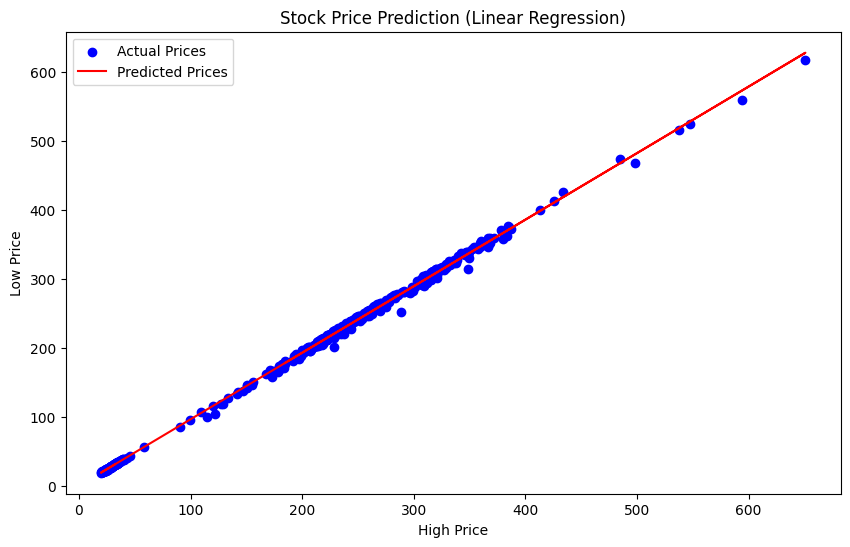

In [58]:
plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, color='blue', label='Actual Prices')
plt.plot(X_test, y_pred, color='red', label='Predicted Prices')
plt.title("Stock Price Prediction (Linear Regression)")
plt.xlabel("High Price")
plt.ylabel("Low Price")
plt.legend()
plt.show()